# 🌋 Análisis Histórico de Sismos en Perú
## Notebook de exposición — Preguntas de Negocio

Proyecto aplicativo — Lenguaje de Ciencia de Datos II · CIBERTEC

Este notebook cubre el ciclo completo pedido para la exposición: **ingesta → exploración
→ feature engineering → visualización estratégica**. Los 5 gráficos aquí generados
responden, cada uno, a una pregunta de negocio del proyecto y se generan de forma
**independiente al dashboard de la Data App** (que usa Plotly): aquí se usa
Matplotlib/Seaborn para el análisis exploratorio de exposición.

| # | Sección | Contenido |
|---|---------|-----------|
| 1 | Ingesta | Carga desde caché Parquet (o API USGS) con manejo de errores |
| 2 | Exploración | Feature engineering orientado a las preguntas de negocio |
| 3 | Visualización estratégica | 5 gráficos, cada uno justificado |


---
## ⚙️ Sección 1: Ingesta desde la API de la USGS con caché Parquet

Reutilizamos la capa de ingesta del proyecto (`ingesta/cliente_usgs.py`): si ya existe
un Parquet cacheado, se usa directamente; si no, se descarga desde la API de la USGS
con reintentos y backoff exponencial ante errores de red.


In [1]:
import sys
sys.path.insert(0, "..")  # raíz del proyecto, para importar ingesta/ y transformacion/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ingesta.cliente_usgs import ejecutar_ingesta_completa, RUTA_PARQUET
from transformacion.esquemas import validar_sismos_crudos, validar_sismos_enriquecidos
from transformacion.procesamiento import transformar_sismos

sns.set_style("whitegrid")
PALETA = "flare"
COLOR_PRINCIPAL = "#C0392B"


Matplotlib is building the font cache; this may take a moment.


In [2]:
try:
    ruta = ejecutar_ingesta_completa(forzar=False)
    print(f">>> Datos disponibles en: {ruta}")
except Exception as error:
    print(f">>> No se pudo completar la ingesta en vivo ({error}).")
    print(">>> Se continúa con el Parquet cacheado en datos/datos_raw/, si existe.")

df_crudo = pd.read_parquet(RUTA_PARQUET)
df_crudo = validar_sismos_crudos(df_crudo)
print(f"\n>>> Dataset cargado y validado con Pandera: {df_crudo.shape[0]} filas x {df_crudo.shape[1]} columnas")
df_crudo.head()


2026-08-16 22:23:02 | INFO     | Se encontró caché Parquet existente en e:\I202511324\Desktop\prueba_defensa\sismos-peru-app\datos\datos_raw\sismos_peru.parquet. Se omite la descarga.
>>> Datos disponibles en: e:\I202511324\Desktop\prueba_defensa\sismos-peru-app\datos\datos_raw\sismos_peru.parquet

>>> Dataset cargado y validado con Pandera: 10955 filas x 16 columnas


,id_usgs,fecha_hora_utc,magnitud,tipo_magnitud,lugar,profundidad_km,longitud,latitud,alerta_tsunami,significancia,num_estaciones,gap_azimutal,rms,estado_revision,tipo_evento,url_detalle
0,usp0000j31,1976-08-28 21:50:37.800000+00:00,5.1,mb,"38 km W of Paramonga, Peru",59.0,-78.189,-10.669,0,400.0,NaN,NaN,NaN,reviewed,earthquake,https://earthquake.usgs.gov/earthquakes/eventp...
1,usp0000j6k,1976-09-03 17:57:06.800000+00:00,5.2,mb,"18 km NE of Quicacha, Peru",63.0,-73.685,-15.496,0,416.0,NaN,NaN,NaN,reviewed,earthquake,https://earthquake.usgs.gov/earthquakes/eventp...
2,usp0000jd5,1976-09-14 14:27:18.100000+00:00,5.0,mb,"18 km ENE of Acarí, Peru",98.0,-74.448,-15.372,0,385.0,NaN,NaN,NaN,reviewed,earthquake,https://earthquake.usgs.gov/earthquakes/eventp...
3,usp0000jfw,1976-09-18 07:20:34.400000+00:00,4.7,mb,"46 km E of Estique, Peru",55.0,-69.580,-17.525,0,340.0,NaN,NaN,NaN,reviewed,earthquake,https://earthquake.usgs.gov/earthquakes/eventp...
4,usp0000jnt,1976-09-28 13:52:27.900000+00:00,5.0,mb,"81 km SE of Mazo Cruz, Peru",132.0,-69.201,-17.288,0,385.0,NaN,NaN,NaN,reviewed,earthquake,https://earthquake.usgs.gov/earthquakes/eventp...


---
## 🔍 Sección 2: Exploración y Feature Engineering orientado al dashboard

### ¿Qué preguntas de negocio responde este análisis?

1. ¿Cómo ha evolucionado la frecuencia de los terremotos en el Perú durante los últimos 50 años?
2. ¿Qué regiones presentan mayor actividad sísmica?
3. ¿Cuál es la distribución de las magnitudes registradas?
4. ¿Existen períodos del año con mayor ocurrencia de sismos?
5. ¿Qué relación existe entre la profundidad y la magnitud de los terremotos?

Para responderlas se agregan columnas: año, mes, estación del año, década, país,
**departamento** (asignado por cercanía del epicentro al centroide del departamento) y
categoría de profundidad. Toda esta lógica vive en `transformacion/procesamiento.py`.


In [3]:
df = transformar_sismos(df_crudo)
df = validar_sismos_enriquecidos(df)
print(f">>> Dataset enriquecido y validado: {df.shape[0]} filas x {df.shape[1]} columnas")
df[["fecha_hora_utc", "magnitud", "profundidad_km", "departamento", "anio", "nombre_mes", "estacion_anio"]].head()


2026-08-16 22:23:02 | INFO     | Iniciando transformación de 10955 registros...
2026-08-16 22:23:03 | INFO     | Transformación completa: 10955 filas x 25 columnas
>>> Dataset enriquecido y validado: 10955 filas x 25 columnas


,fecha_hora_utc,magnitud,profundidad_km,departamento,anio,nombre_mes,estacion_anio
0,1976-08-28 21:50:37.800000+00:00,5.1,59.0,Áncash,1976,Agosto,Invierno
1,1976-09-03 17:57:06.800000+00:00,5.2,63.0,Apurímac,1976,Septiembre,Primavera
2,1976-09-14 14:27:18.100000+00:00,5.0,98.0,Ica,1976,Septiembre,Primavera
3,1976-09-18 07:20:34.400000+00:00,4.7,55.0,Tacna,1976,Septiembre,Primavera
4,1976-09-28 13:52:27.900000+00:00,5.0,132.0,Tacna,1976,Septiembre,Primavera


In [4]:
print("=" * 60)
print("RESUMEN DEL DATASET")
print("=" * 60)
print(f"Total de sismos        : {df.shape[0]}")
print(f"Rango de años          : {df['anio'].min()} - {df['anio'].max()}")
print(f"Departamentos distintos: {df['departamento'].nunique()}")
print(f"Departamento más activo: {df['departamento'].value_counts().idxmax()}")
print(f"Magnitud promedio      : {df['magnitud'].mean():.2f}")
print(f"Magnitud máxima        : {df['magnitud'].max():.1f}")
print(f"Profundidad promedio   : {df['profundidad_km'].mean():.1f} km")

nulos = df.isnull().sum()
print("\nValores nulos por columna:")
print(nulos[nulos > 0] if nulos.any() else ">>> Sin valores nulos relevantes")


RESUMEN DEL DATASET
Total de sismos        : 10955
Rango de años          : 1976 - 2026
Departamentos distintos: 25
Departamento más activo: Tumbes
Magnitud promedio      : 4.56
Magnitud máxima        : 8.4
Profundidad promedio   : 83.1 km

Valores nulos por columna:
num_estaciones    6050
gap_azimutal      4308
rms                622
dtype: int64


---
## 📊 Sección 3: Visualización Estratégica

### Del objetivo al gráfico correcto

Cada gráfico responde a **una** pregunta de negocio específica. Se justifica el
objetivo analítico y la decisión de diseño antes de generarlo, y se exporta como PNG
para la presentación (`presentacion/`).


#### 📈 Gráfico 1 — Evolución de la frecuencia de sismos (últimos 50 años)

**Pregunta de negocio 1:** ¿Cómo ha evolucionado la frecuencia de los terremotos en el
Perú durante los últimos 50 años?

**Objetivo:** mostrar tendencia temporal. **Decisión:** serie de tiempo anual +
media móvil de 5 años para suavizar el ruido interanual y resaltar la tendencia de
fondo.


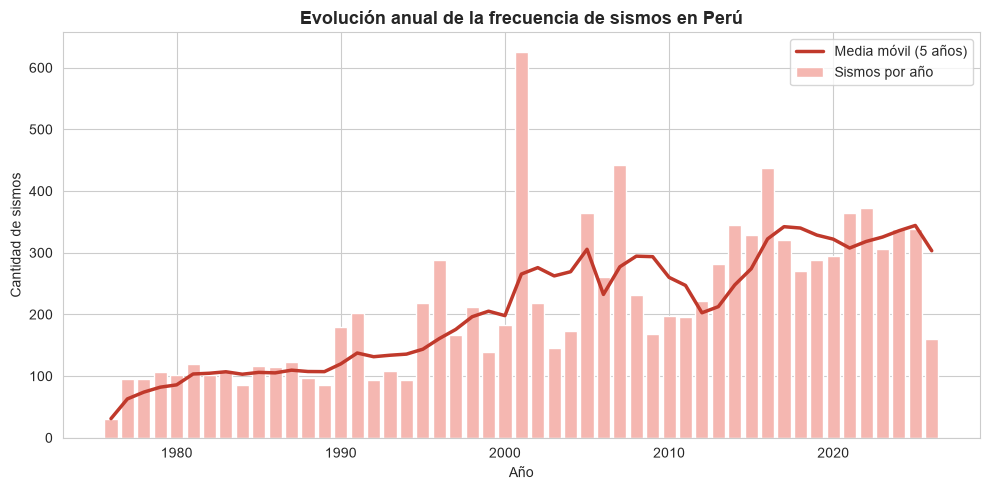

In [5]:
conteo_anual = df.groupby("anio").size().rename("cantidad_sismos").reset_index()
conteo_anual["media_movil_5a"] = conteo_anual["cantidad_sismos"].rolling(5, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(conteo_anual["anio"], conteo_anual["cantidad_sismos"], color="#F5B7B1", label="Sismos por año")
ax.plot(conteo_anual["anio"], conteo_anual["media_movil_5a"], color=COLOR_PRINCIPAL, linewidth=2.5, label="Media móvil (5 años)")
ax.set_title("Evolución anual de la frecuencia de sismos en Perú", fontsize=13, fontweight="bold")
ax.set_xlabel("Año")
ax.set_ylabel("Cantidad de sismos")
ax.legend()
plt.tight_layout()
plt.savefig("imagenes_graficos/grafico_1_evolucion_frecuencia.png", dpi=150)
plt.show()


#### 🗺️ Gráfico 2 — Regiones con mayor actividad sísmica

**Pregunta de negocio 2:** ¿Qué regiones presentan mayor actividad sísmica?

**Objetivo:** comparar categorías (departamentos). **Decisión:** barras horizontales
— mejor lectura de etiquetas largas y facilita el ranking Top 10.


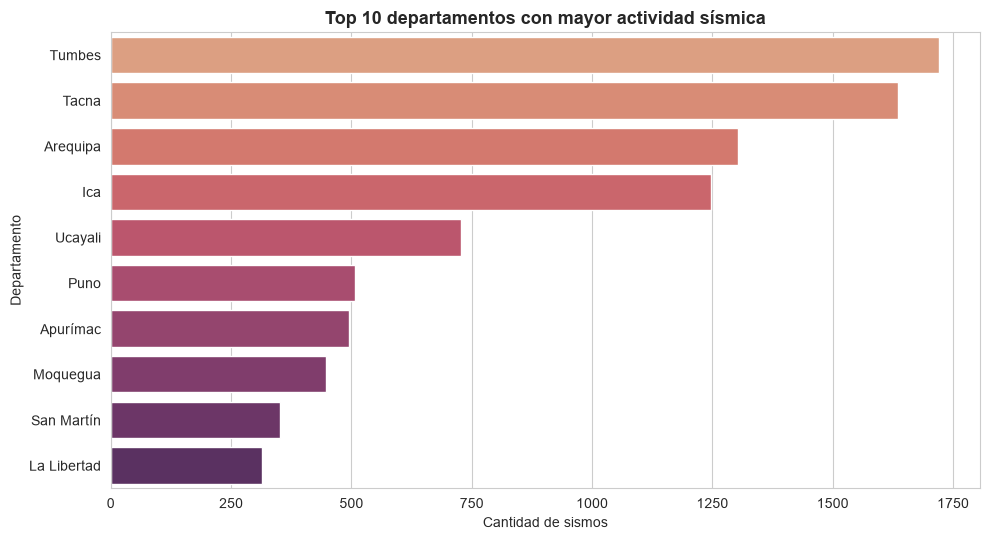

In [6]:
conteo_departamento = (
    df["departamento"].value_counts().head(10).rename("cantidad_sismos").rename_axis("departamento").reset_index()
)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=conteo_departamento, x="cantidad_sismos", y="departamento", hue="departamento",
            palette=PALETA, legend=False, ax=ax)
ax.set_title("Top 10 departamentos con mayor actividad sísmica", fontsize=13, fontweight="bold")
ax.set_xlabel("Cantidad de sismos")
ax.set_ylabel("Departamento")
plt.tight_layout()
plt.savefig("imagenes_graficos/grafico_2_regiones_actividad.png", dpi=150)
plt.show()


#### 📐 Gráfico 3 — Distribución de las magnitudes registradas

**Pregunta de negocio 3:** ¿Cuál es la distribución de las magnitudes registradas?

**Objetivo:** mostrar distribución estadística. **Decisión:** histograma + curva de
densidad (KDE) — estándar para visualizar forma, dispersión y sesgo de una variable
continua.


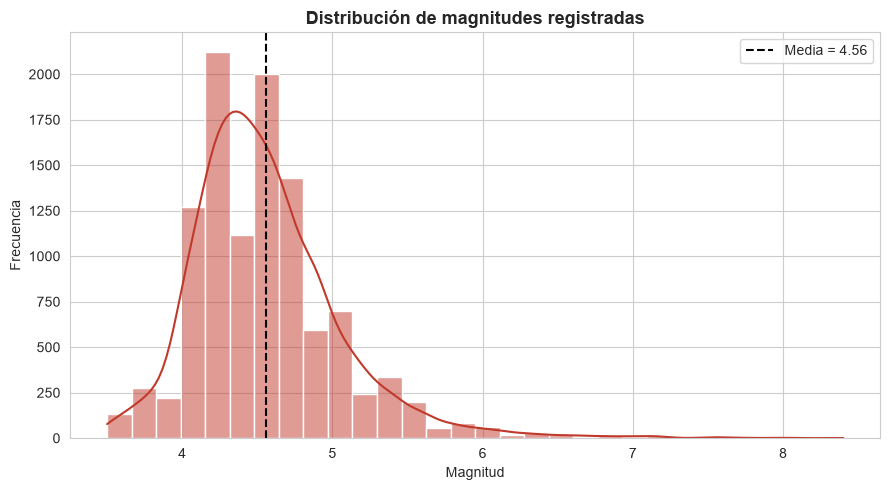

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["magnitud"], bins=30, kde=True, color=COLOR_PRINCIPAL, ax=ax)
ax.axvline(df["magnitud"].mean(), color="black", linestyle="--", label=f"Media = {df['magnitud'].mean():.2f}")
ax.set_title("Distribución de magnitudes registradas", fontsize=13, fontweight="bold")
ax.set_xlabel("Magnitud")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.tight_layout()
plt.savefig("imagenes_graficos/grafico_3_distribucion_magnitudes.png", dpi=150)
plt.show()


#### 📅 Gráfico 4 — Estacionalidad: ¿hay meses con mayor ocurrencia?

**Pregunta de negocio 4:** ¿Existen períodos del año con mayor ocurrencia de sismos?

**Objetivo:** comparar un ciclo estacional (12 categorías ordenadas). **Decisión:**
barras por mes en orden calendario, coloreadas por intensidad — permite detectar
rápidamente meses pico.


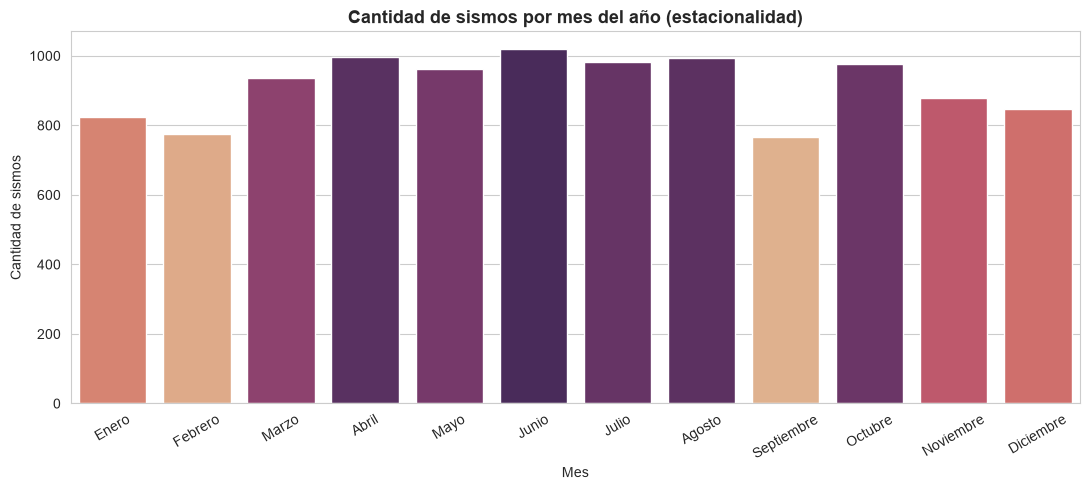

In [8]:
orden_meses = ["Enero","Febrero","Marzo","Abril","Mayo","Junio",
               "Julio","Agosto","Septiembre","Octubre","Noviembre","Diciembre"]
conteo_mes = df.groupby("nombre_mes").size().reindex(orden_meses).rename("cantidad_sismos").reset_index()
conteo_mes.columns = ["mes", "cantidad_sismos"]

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=conteo_mes, x="mes", y="cantidad_sismos", hue="cantidad_sismos",
            palette=PALETA, legend=False, ax=ax)
ax.set_title("Cantidad de sismos por mes del año (estacionalidad)", fontsize=13, fontweight="bold")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad de sismos")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("imagenes_graficos/grafico_4_estacionalidad.png", dpi=150)
plt.show()


#### 🌐 Gráfico 5 — Relación entre profundidad y magnitud

**Pregunta de negocio 5:** ¿Qué relación existe entre la profundidad y la magnitud de
los terremotos?

**Objetivo:** explorar correlación entre dos variables cuantitativas. **Decisión:**
scatter plot con línea de regresión — ideal para detectar patrones, dispersión y
tendencia lineal (o su ausencia).


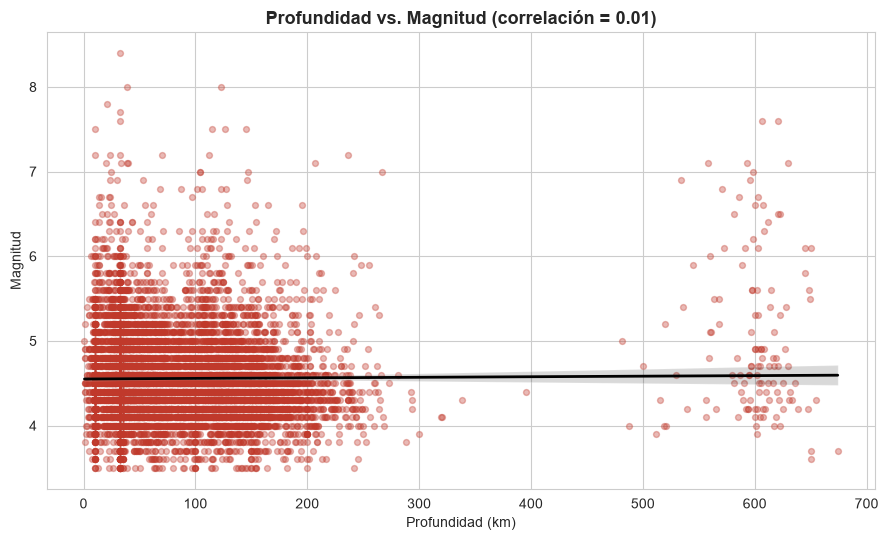

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.regplot(
    data=df, x="profundidad_km", y="magnitud",
    scatter_kws={"alpha": 0.35, "color": COLOR_PRINCIPAL, "s": 18},
    line_kws={"color": "black", "linewidth": 2}, ax=ax,
)
correlacion = df["profundidad_km"].corr(df["magnitud"])
ax.set_title(f"Profundidad vs. Magnitud (correlación = {correlacion:.2f})", fontsize=13, fontweight="bold")
ax.set_xlabel("Profundidad (km)")
ax.set_ylabel("Magnitud")
plt.tight_layout()
plt.savefig("imagenes_graficos/grafico_5_profundidad_magnitud.png", dpi=150)
plt.show()


---
## ✅ Resumen

1. **Ingesta** desde la API de la USGS con caché Parquet y manejo de errores (reintentos, backoff).
2. **Exploración** y feature engineering orientado a las 5 preguntas de negocio del dashboard.
3. **Visualización estratégica**: 5 gráficos, cada uno justificado y respondiendo una pregunta de negocio.
4. Los gráficos se exportaron a `imagenes_graficos/` para reutilizarse en la presentación PPTX,
   generados de forma **independiente al dashboard** (Matplotlib/Seaborn vs. Plotly en la app).
